<a href="https://colab.research.google.com/github/AndruTP/DSA-Siniestralidad-Bogota/blob/main/ENTRENAMIENTO_MODELOS_ENTREGA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción mensual de siniestros con víctimas por localidad en Bogotá

**Despliegue de Soluciones Analíticas · Entrega 2**  
**Entrenamiento y evaluación de modelos supervisados**

El proyecto estima la cantidad mensual de siniestros viales registrados con heridos o fallecidos en 19 localidades urbanas de Bogotá, con un horizonte de un mes. El pronóstico se plantea como apoyo para identificar cambios de volumen frente al comportamiento histórico y orientar la revisión de prioridades territoriales.

La metodología parte de un panel mensual preparado con datos de la Secretaría Distrital de Movilidad, conserva la separación temporal de entrenamiento, validación y prueba, compara modelos de conteo y evalúa su desempeño global, territorial y entre periodos. La variable objetivo representa **siniestros**, no el número de víctimas; el volumen observado tampoco equivale a una tasa de riesgo ajustada por población o viajes.

**Estructura del estudio:** datos y particiones · modelos iniciales · comportamiento territorial · variabilidad temporal · modelos relativos · comparación · validación expansiva · trazabilidad de experimentos. Los resultados presentados corresponden a **validación 2024**; el conjunto de **2025 permanece reservado** para la evaluación final.

## 1. Carga y verificación del conjunto de modelamiento

Se importa `dataset_modelado_2017_2025.csv`, obtenido de la agregación de siniestros por localidad y mes. La celda convierte el periodo a fecha, organiza la información y comprueba el número de observaciones, localidades, registros duplicados y valores faltantes. Se calcula también una huella SHA-256 del archivo, que permite identificar de manera exacta la versión utilizada en los experimentos.

In [ ]:
# 1. CARGA DEL DATASET PARA ENTRENAMIENTO
# Proyecto Siniestralidad vial en Bogotá
import pandas as pd
from pathlib import Path
CARPETA_SALIDA = Path("/content") if Path("/content").is_dir() else Path.cwd()

rutas = [Path("/content/dataset_modelado_2017_2025.csv"), Path("dataset_modelado_2017_2025.csv")]
ruta = next((p for p in rutas if p.exists()), rutas[0])
if not ruta.exists():
    raise FileNotFoundError("Suba dataset_modelado_2017_2025.csv a Colab antes de ejecutar.")

# Se carga la información preparada
df = pd.read_csv(ruta, encoding="utf-8-sig")

# Convertir la fecha a formato temporal
df["PERIODO"] = pd.to_datetime(df["PERIODO"])

# Organizar los registros cronológicamente
df = df.sort_values(["LOCALIDAD", "PERIODO"]).reset_index(drop=True)

# Verificaciones iniciales
assert len(df) == 2052
assert df["LOCALIDAD"].nunique() == 19
assert df.isna().sum().sum() == 0
assert not df.duplicated(["LOCALIDAD", "PERIODO"]).any()

print("DATASET CARGADO CORRECTAMENTE")
print("Registros:", len(df))
print("Columnas:", len(df.columns))
print("Localidades:", df["LOCALIDAD"].nunique())
print("Periodo:", df["PERIODO"].min(), "a", df["PERIODO"].max())

display(df.head())

# Huella para vincular resultados y versión concreta del dataset
import hashlib
with ruta.open("rb") as f:
    huella_dataset = hashlib.sha256(f.read()).hexdigest()
print("SHA-256 del dataset:", huella_dataset)

DATASET CARGADO CORRECTAMENTE
Registros: 2052
Columnas: 15
Localidades: 19
Periodo: 2017-01-01 00:00:00 a 2025-12-01 00:00:00


,LOCALIDAD,PERIODO,SINIESTROS,MES,ANIO,MES_SIN,MES_COS,LAG_1,LAG_3,LAG_6,LAG_12,MEDIA_MOVIL_3,MEDIA_MOVIL_6,MEDIA_MOVIL_12,PERIODO_2020_2021
0,ANTONIO NARIÑO,2017-01-01,28,1,2017,0.500000,8.660254e-01,28.0,38.0,46.0,30.0,36.000000,42.666667,39.166667,0
1,ANTONIO NARIÑO,2017-02-01,28,2,2017,0.866025,5.000000e-01,28.0,42.0,66.0,14.0,32.666667,39.666667,39.000000,0
2,ANTONIO NARIÑO,2017-03-01,46,3,2017,1.000000,6.123234e-17,28.0,28.0,36.0,32.0,28.000000,33.333333,40.166667,0
3,ANTONIO NARIÑO,2017-04-01,42,4,2017,0.866025,-5.000000e-01,46.0,28.0,38.0,36.0,34.000000,35.000000,41.333333,0
4,ANTONIO NARIÑO,2017-05-01,28,5,2017,0.500000,-8.660254e-01,42.0,28.0,42.0,52.0,38.666667,35.666667,41.833333,0


SHA-256 del dataset: 17277bb9603aab18c2b1e96975f1b77d899f40e85a079fa3dd3edf199da3fd34


El conjunto contiene **2.052 observaciones, 15 columnas y 19 localidades**, sin registros repetidos por localidad–mes ni valores faltantes. El periodo disponible se extiende de enero de 2017 a diciembre de 2025. La huella SHA-256 queda asociada al archivo cargado y debe conservarse junto con los resultados del experimento.

### 1.1. Procedencia, nivel de análisis y actualización de datos

La fuente original es el conjunto **ACCIDENTE** de la Secretaría Distrital de Movilidad de Bogotá, donde cada registro representa un siniestro reportado. El panel de modelamiento agrega los registros clasificados como **CON HERIDOS** o **CON MUERTOS** por localidad y mes; se excluyen los de **SOLO DAÑOS** debido a la discontinuidad de registro documentada desde 2022.

Los rezagos y medias móviles se construyen con meses anteriores al periodo de pronóstico. El panel contiene datos de 2017 a 2025, mientras que 2016 proporciona el historial necesario para los primeros rezagos. Sumapaz se excluye del modelamiento por la escasez de registros mensuales. La fuente puede recibir actualizaciones; por tanto, el origen, la fecha de extracción y la huella del archivo deben acompañar las versiones de datos utilizadas.

**Fuente:** [Secretaría Distrital de Movilidad, conjunto ACCIDENTE](https://datos.movilidadbogota.gov.co/datasets/accidente-1/explore). La incorporación periódica de nuevos datos y un eventual reentrenamiento corresponden a etapas operativas posteriores; no se implementan de forma automática en este cuaderno.

## 2. Partición cronológica

Los datos se separan en **entrenamiento (2017–2023)**, **validación (2024)** y **prueba final (2025)**. Esta división mantiene el orden temporal y evita seleccionar un modelo con los resultados del año reservado para prueba. La validación corresponde a estimaciones mensuales sucesivas, empleando los conteos de los meses previos que ya estarían disponibles al cierre de cada periodo.

In [ ]:
# 2. PARTICIÓN CRONOLÓGICA DEL DATASET
# Entrenamiento: enero 2017 - diciembre 2023
train = df[df["ANIO"].between(2017, 2023)].copy()

# Validación: enero - diciembre 2024
val = df[df["ANIO"] == 2024].copy()

# Prueba final: enero - diciembre 2025
test = df[df["ANIO"] == 2025].copy()

# Verificar el número de observaciones
assert len(train) == 1596
assert len(val) == 228
assert len(test) == 228

# Comprobar que los periodos no se mezclen
assert train["PERIODO"].max() < val["PERIODO"].min()
assert val["PERIODO"].max() < test["PERIODO"].min()

# Comprobar que no se pierdan registros
assert len(train) + len(val) + len(test) == len(df)

print("PARTICIÓN CRONOLÓGICA VALIDADA")
print("Entrenamiento:", len(train), "registros")
print("Validación:", len(val), "registros")
print("Prueba final:", len(test), "registros")
print("Total:", len(train) + len(val) + len(test))

PARTICIÓN CRONOLÓGICA VALIDADA
Entrenamiento: 1596 registros
Validación: 228 registros
Prueba final: 228 registros
Total: 2052


El entrenamiento reúne **1.596 registros**, mientras que la validación y la prueba final contienen **228 registros cada una**. Las comprobaciones confirman que las fechas no se superponen y que las tres particiones cubren el panel completo.

## 3. Variables explicativas y variable objetivo

La variable objetivo es `SINIESTROS`, definida como el conteo mensual de siniestros con víctimas. Las variables explicativas incluyen la localidad, indicadores de calendario, rezagos de 1, 3, 6 y 12 meses, medias móviles históricas y un indicador del periodo 2020–2021. `PERIODO` se conserva para ordenar y verificar la secuencia de observaciones, pero no se entrega directamente como variable del modelo.

Los indicadores históricos requieren disponer del registro mensual previo, por lo que su cálculo debe reproducirse también al utilizar el modelo fuera del entorno de entrenamiento.

In [ ]:
# 3. DEFINICIÓN DE VARIABLES PREDICTORAS Y OBJETIVO
# Variables utilizadas para predecir
variables_predictoras = ["LOCALIDAD","MES","ANIO","MES_SIN","MES_COS","LAG_1","LAG_3","LAG_6","LAG_12","MEDIA_MOVIL_3","MEDIA_MOVIL_6","MEDIA_MOVIL_12","PERIODO_2020_2021"]
variable_objetivo = "SINIESTROS"

# Separar las variables para cada conjunto
X_train = train[variables_predictoras].copy()
y_train = train[variable_objetivo].copy()
X_val = val[variables_predictoras].copy()
y_val = val[variable_objetivo].copy()
X_test = test[variables_predictoras].copy()
y_test = test[variable_objetivo].copy()

# Validaciones de seguridad
assert variable_objetivo not in X_train.columns
assert "PERIODO" not in X_train.columns
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)
assert (y_train >= 0).all()

print("VARIABLES PREPARADAS CORRECTAMENTE")
print("Predictores:", len(variables_predictoras))
print("Variable objetivo:", variable_objetivo)

print("\nDimensiones:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nVariables utilizadas:")
print(X_train.dtypes)

VARIABLES PREPARADAS CORRECTAMENTE
Predictores: 13
Variable objetivo: SINIESTROS

Dimensiones:
X_train: (1596, 13)
X_val: (228, 13)
X_test: (228, 13)

Variables utilizadas:
LOCALIDAD             object
MES                    int64
ANIO                   int64
MES_SIN              float64
MES_COS              float64
LAG_1                float64
LAG_3                float64
LAG_6                float64
LAG_12               float64
MEDIA_MOVIL_3        float64
MEDIA_MOVIL_6        float64
MEDIA_MOVIL_12       float64
PERIODO_2020_2021      int64
dtype: object


Se obtienen **13 variables explicativas** y una variable objetivo para cada partición, con dimensiones de 1.596 × 13 en entrenamiento y 228 × 13 tanto en validación como en prueba. La localidad permanece identificada como categórica para transformarse dentro de cada procedimiento de ajuste.

## 4. Modelo inicial: Gradient Boosting con pérdida Poisson

Se ajusta un modelo basado en árboles para pronosticar conteos no negativos. La localidad se transforma mediante codificación categórica y el procesamiento se aprende únicamente con los registros de entrenamiento. El desempeño se evalúa en 2024 mediante MAE, RMSE y sesgo medio; el MAE es la medida principal de comparación.

La referencia de validación es la media móvil de 12 meses, cuyo MAE es **7,0146**. El criterio propuesto en la primera entrega exige una disminución de al menos 10 %, equivalente a un MAE máximo aproximado de **6,3132**.

In [ ]:
# 4. PRIMER MODELO: GRADIENT BOOSTING CON POISSON
# Se importan las librerias necesarias
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Separar variables categóricas y numéricas
categoricas = ["LOCALIDAD"]
numericas = [
    columna for columna in variables_predictoras
    if columna not in categoricas
]

# Preparar la transformación de variables
preprocesador = ColumnTransformer(
    transformers=[
        ("localidad",
         OneHotEncoder(
             handle_unknown="ignore",
             sparse_output=False
         ),
         categoricas),
        ("numericas", "passthrough", numericas)
    ]
)

# Construir el modelo
modelo_poisson = Pipeline([
    ("preprocesamiento", preprocesador),
    ("modelo", HistGradientBoostingRegressor(
        loss="poisson",
        max_iter=250,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=15,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42
    ))
])

# Entrenar exclusivamente con datos de 2017-2023
modelo_poisson.fit(X_train, y_train)

# Predecir sobre los datos de validación de 2024
pred_val_poisson = modelo_poisson.predict(X_val)

# Calcular las métricas
mae_poisson = mean_absolute_error(y_val, pred_val_poisson)
rmse_poisson = np.sqrt(mean_squared_error(y_val, pred_val_poisson))
sesgo_poisson = np.mean(pred_val_poisson - y_val.to_numpy())

# Comparar con la mejor línea base de 2024
mae_base = mean_absolute_error(y_val, val["MEDIA_MOVIL_12"])
meta_mae = mae_base * 0.90

print("PRIMER MODELO ENTRENADO")
print("Modelo: Gradient Boosting Poisson")
print("Observaciones de entrenamiento:", len(X_train))
print("Observaciones de validación:", len(X_val))

print("\nRESULTADOS DE VALIDACIÓN - 2024")
print(f"MAE del modelo: {mae_poisson:.4f}")
print(f"RMSE del modelo: {rmse_poisson:.4f}")
print(f"Sesgo del modelo: {sesgo_poisson:.4f}")
print(f"MAE línea base: {mae_base:.4f}")
print(f"Meta de MAE: {meta_mae:.4f}")

print("\n¿Cumple la meta del proyecto?",
      "SÍ" if mae_poisson <= meta_mae else "NO")

# Comparación de predicciones
resultados_poisson = val[
    ["LOCALIDAD", "PERIODO", "SINIESTROS"]
].copy()

resultados_poisson["PREDICCION"] = pred_val_poisson

display(resultados_poisson.head(10))

PRIMER MODELO ENTRENADO
Modelo: Gradient Boosting Poisson
Observaciones de entrenamiento: 1596
Observaciones de validación: 228

RESULTADOS DE VALIDACIÓN - 2024
MAE del modelo: 7.1921
RMSE del modelo: 10.1549
Sesgo del modelo: -0.1126
MAE línea base: 7.0146
Meta de MAE: 6.3132

¿Cumple la meta del proyecto? NO


,LOCALIDAD,PERIODO,SINIESTROS,PREDICCION
84,ANTONIO NARIÑO,2024-01-01,20,20.754093
85,ANTONIO NARIÑO,2024-02-01,29,21.829124
86,ANTONIO NARIÑO,2024-03-01,20,24.084023
87,ANTONIO NARIÑO,2024-04-01,22,17.818874
88,ANTONIO NARIÑO,2024-05-01,21,21.153960
89,ANTONIO NARIÑO,2024-06-01,19,24.150539
90,ANTONIO NARIÑO,2024-07-01,21,20.796058
91,ANTONIO NARIÑO,2024-08-01,20,23.796292
92,ANTONIO NARIÑO,2024-09-01,32,19.980948
93,ANTONIO NARIÑO,2024-10-01,24,23.189689


En 2024, Gradient Boosting Poisson obtiene **MAE 7,1921**, **RMSE 10,1549** y **sesgo −0,1126**. Su MAE supera el de la referencia (7,0146), por lo que no cumple el criterio de mejora del 10 %. El sesgo medio cercano a cero no descarta errores importantes en determinadas localidades.

## 5. Evaluación por localidad

Se calcula el error absoluto promedio y el sesgo del modelo inicial para cada localidad, junto con el error de la referencia histórica. Esta desagregación permite reconocer si la precisión global oculta diferencias territoriales, especialmente en localidades con volúmenes elevados de siniestros.

In [ ]:
# 5. EVALUACIÓN DEL MODELO POR LOCALIDAD
# Recuperar los resultados del modelo
diagnostico = resultados_poisson.copy()

# Agregar la referencia de 12 meses
diagnostico["BASE_12"] = val.loc[diagnostico.index, "MEDIA_MOVIL_12"]

# Calcular errores del modelo
diagnostico["ERROR"] = (diagnostico["PREDICCION"] - diagnostico["SINIESTROS"])
diagnostico["ERROR_ABS"] = diagnostico["ERROR"].abs()

# Calcular errores de la línea base
diagnostico["ERROR_ABS_BASE"] = (diagnostico["BASE_12"] - diagnostico["SINIESTROS"]).abs()

# Resumen por localidad
resumen_localidades = diagnostico.groupby(
    "LOCALIDAD", as_index=False
).agg(
    MAE_MODELO=("ERROR_ABS", "mean"),
    MAE_BASE=("ERROR_ABS_BASE", "mean"),
    SESGO=("ERROR", "mean"),
    OBSERVACIONES=("ERROR", "size")
)

# Identificar dónde mejora la línea base
resumen_localidades["MEJORA_PCT"] = (
    1 - resumen_localidades["MAE_MODELO"]
    / resumen_localidades["MAE_BASE"]
) * 100

resumen_localidades = resumen_localidades.sort_values("MAE_MODELO", ascending=False)

print("EVALUACIÓN POR LOCALIDAD - 2024")
print("Localidades evaluadas:",
      len(resumen_localidades))

print("Localidades donde el modelo supera la base:",
      (resumen_localidades["MAE_MODELO"]
       < resumen_localidades["MAE_BASE"]).sum())

display(resumen_localidades.round(2))

EVALUACIÓN POR LOCALIDAD - 2024
Localidades evaluadas: 19
Localidades donde el modelo supera la base: 5


,LOCALIDAD,MAE_MODELO,MAE_BASE,SESGO,OBSERVACIONES,MEJORA_PCT
8,KENNEDY,17.07,15.76,-1.96,12,-8.26
7,FONTIBON,12.53,11.21,0.20,12,-11.80
10,PUENTE ARANDA,11.24,10.25,-1.90,12,-9.66
17,USAQUEN,10.39,9.51,-5.13,12,-9.24
14,SUBA,8.92,12.65,0.17,12,29.48
6,ENGATIVA,8.83,8.01,6.35,12,-10.13
2,BOSA,7.24,7.20,0.21,12,-0.59
13,SANTA FE,7.14,5.84,-0.51,12,-22.20
9,LOS MARTIRES,6.61,6.44,0.92,12,-2.62
15,TEUSAQUILLO,6.25,6.69,3.46,12,6.60


El modelo inicial mejora la media móvil en **5 de 19 localidades**. En **Kennedy** presenta MAE 17,07, mientras que en **Suba** obtiene 8,92 frente a 12,65 de la referencia. En **Engativá** el sesgo es positivo (+6,35) y en **Usaquén** negativo (−5,13), señal de que la compensación de errores globales oculta comportamientos diferentes entre territorios.

## 6. Regresión binomial negativa NB2

El análisis exploratorio identificó sobredispersión en los conteos, por lo que se evalúa una regresión binomial negativa. En esta primera especificación se emplean los rezagos originales y una variable temporal de año, con una transformación de variables ajustada exclusivamente sobre el entrenamiento. La convergencia del algoritmo se verifica antes de analizar las predicciones.

El resultado de esta especificación se conserva como comparación inicial de la familia NB2 y posteriormente se contrasta con una versión transformada.

In [ ]:
# 6. SEGUNDO MODELO: REGRESIÓN BINOMIAL NEGATIVA
# Se importan las librerias
import statsmodels.api as sm
from statsmodels.discrete.discrete_model import NegativeBinomial
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#Preparar las variables
preprocesador_nb = ColumnTransformer([
    ("localidad",OneHotEncoder(drop="first",handle_unknown="ignore",sparse_output=False),
        ["LOCALIDAD"]),("numericas",StandardScaler(),numericas)])

# Ajustar transformaciones solo con entrenamiento
X_train_nb = preprocesador_nb.fit_transform(X_train)
X_val_nb = preprocesador_nb.transform(X_val)

# Agregar intercepto
X_train_nb = sm.add_constant(X_train_nb, has_constant="add")
X_val_nb = sm.add_constant(X_val_nb, has_constant="add")

# 2. Construir y entrenar el modelo NB2
modelo_nb = NegativeBinomial(y_train.to_numpy(),X_train_nb,loglike_method="nb2")
resultado_nb = modelo_nb.fit(method="bfgs",maxiter=500,disp=False)

# 3. Verificar convergencia
convergio = resultado_nb.mle_retvals["converged"]
print("Convergencia:", convergio)

if not convergio:
    raise RuntimeError(
        "El modelo no convergió; revisar antes de evaluar."
    )

# 4. Predecir sobre validación 2024
pred_val_nb = np.asarray(resultado_nb.predict(X_val_nb))
assert np.isfinite(pred_val_nb).all()
assert (pred_val_nb >= 0).all()

# 5. Calcular métricas
mae_nb = mean_absolute_error(y_val, pred_val_nb)
rmse_nb = np.sqrt(mean_squared_error(y_val, pred_val_nb))
sesgo_nb = np.mean(pred_val_nb - y_val.to_numpy())
alpha_nb = resultado_nb.params[-1]

# 6. Comparar los modelos
print("\nSEGUNDO MODELO ENTRENADO")
print("Modelo: Regresión Binomial Negativa NB2")
print(f"Parámetro de dispersión: {alpha_nb:.4f}")
print("\nRESULTADOS DE VALIDACIÓN - 2024")
print(f"MAE Binomial Negativa: {mae_nb:.4f}")
print(f"RMSE: {rmse_nb:.4f}")
print(f"Sesgo: {sesgo_nb:.4f}")
print(f"MAE Gradient Boosting: {mae_poisson:.4f}")
print(f"MAE línea base: {mae_base:.4f}")
print(f"Meta del proyecto: {meta_mae:.4f}")
print("\n¿Cumple la meta?",
      "SÍ" if mae_nb <= meta_mae else "NO")

Convergencia: True

SEGUNDO MODELO ENTRENADO
Modelo: Regresión Binomial Negativa NB2
Parámetro de dispersión: 0.0413

RESULTADOS DE VALIDACIÓN - 2024
MAE Binomial Negativa: 8.7144
RMSE: 13.5363
Sesgo: -5.3913
MAE Gradient Boosting: 7.1921
MAE línea base: 7.0146
Meta del proyecto: 6.3132

¿Cumple la meta? NO


El ajuste converge, con parámetro de dispersión aproximado de **0,0413**, pero alcanza **MAE 8,7144**, **RMSE 13,5363** y **sesgo −5,3913** en 2024. La subestimación media y la diferencia frente a Gradient Boosting justifican evaluar una segunda formulación de esta familia, sin descartar su utilidad únicamente por este resultado.

## 7. Comparación inicial de alternativas

Se reúnen las métricas de la media móvil de 12 meses, Gradient Boosting Poisson y la regresión binomial negativa. Las tres opciones se comparan sobre las mismas 228 observaciones de 2024; la mejora porcentual se calcula respecto al MAE de la referencia. Un porcentaje negativo indica mayor error que la media móvil.

In [ ]:
# 7. COMPARACIÓN DE MODELOS - VALIDACIÓN 2024
# Valores reales y predicciones
reales = y_val.to_numpy()

predicciones = {
    "Media móvil 12 meses": val["MEDIA_MOVIL_12"].to_numpy(),
    "Gradient Boosting Poisson": pred_val_poisson,
    "Binomial Negativa NB2": pred_val_nb
}

# Calcular las métricas de cada alternativa
comparacion = []
for nombre, pred in predicciones.items():
    pred = np.asarray(pred)
    assert len(pred) == len(reales)
    assert np.isfinite(pred).all()

    comparacion.append({
        "MODELO": nombre,
        "MAE": mean_absolute_error(reales, pred),
        "RMSE": np.sqrt(mean_squared_error(reales, pred)),
        "SESGO": np.mean(pred - reales)
    })
tabla_modelos = pd.DataFrame(comparacion)

# Comparar frente a la línea base
mae_referencia = tabla_modelos.loc[tabla_modelos["MODELO"] == "Media móvil 12 meses","MAE"].iloc[0]
tabla_modelos["MEJORA_VS_BASE_%"] = ((mae_referencia - tabla_modelos["MAE"])/ mae_referencia * 100)

# Evaluar el criterio de éxito
meta = mae_referencia * 0.90
tabla_modelos["CUMPLE_META"] = np.where(tabla_modelos["MAE"] <= meta,"SI","NO")

# Ordenar de menor a mayor error
tabla_modelos = tabla_modelos.sort_values("MAE").reset_index(drop=True)

print("COMPARACIÓN DE MODELOS - VALIDACIÓN 2024")
print("Meta de MAE:", round(meta, 4))
print("Convergencia NB2:",
      resultado_nb.mle_retvals.get("converged"))
display(tabla_modelos.round(4))

# Guardar evidencia
tabla_modelos.to_csv((CARPETA_SALIDA / "comparacion_modelos_validacion_2024.csv"),index=False,encoding="utf-8-sig")
print("\nTabla comparativa exportada correctamente")

COMPARACIÓN DE MODELOS - VALIDACIÓN 2024
Meta de MAE: 6.3132
Convergencia NB2: True


,MODELO,MAE,RMSE,SESGO,MEJORA_VS_BASE_%,CUMPLE_META
0,Media móvil 12 meses,7.0146,9.5464,-0.2376,0.0000,NO
1,Gradient Boosting Poisson,7.1921,10.1549,-0.1126,-2.5302,NO
2,Binomial Negativa NB2,8.7144,13.5363,-5.3913,-24.2325,NO



Tabla comparativa exportada correctamente


La media móvil de 12 meses conserva el menor MAE (**7,0146**), seguida por Gradient Boosting (**7,1921**) y NB2 (**8,7144**). Ninguna de las dos alternativas supervisadas iniciales alcanza la meta de **6,3132**; ambas quedan documentadas como puntos de comparación.

## 8. Entrenamiento con una ventana temporal reciente

Se repite Gradient Boosting con los mismos parámetros, pero restringiendo los datos de ajuste a **2021–2023**. La comparación frente a su versión entrenada con **2017–2023** permite valorar si reducir la influencia de los periodos de movilidad anteriores aporta precisión adicional en 2024.

In [ ]:
# 8. EXPERIMENTO: ENTRENAMIENTO CON DATOS 2021-2023
from sklearn.base import clone

# Seleccionar entrenamiento más reciente
filtro_reciente = train["ANIO"].between(2021, 2023)
X_train_reciente = X_train.loc[filtro_reciente].copy()
y_train_reciente = y_train.loc[filtro_reciente].copy()

# Conservar el mismo algoritmo y parámetros
modelo_poisson_reciente = clone(modelo_poisson)

# Entrenar únicamente con 2021-2023
modelo_poisson_reciente.fit(X_train_reciente,y_train_reciente)

# Evaluar sobre 2024
pred_val_reciente = modelo_poisson_reciente.predict(X_val)
mae_reciente = mean_absolute_error(y_val, pred_val_reciente)
rmse_reciente = np.sqrt(mean_squared_error(y_val, pred_val_reciente))
sesgo_reciente = np.mean(pred_val_reciente - y_val.to_numpy())

# Comparación de resultados
print("EXPERIMENTO: PERIODO DE ENTRENAMIENTO")
print("\nModelo original (2017-2023)")
print(f"MAE: {mae_poisson:.4f}")
print("\nModelo reciente (2021-2023)")
print("Registros:", len(X_train_reciente))
print(f"MAE: {mae_reciente:.4f}")
print(f"RMSE: {rmse_reciente:.4f}")
print(f"Sesgo: {sesgo_reciente:.4f}")

print("\nLínea base:", round(mae_base, 4))
print("Meta:", round(meta_mae, 4))
print("\n¿Mejoró frente al modelo original?",
      "SÍ" if mae_reciente < mae_poisson else "NO")
print("¿Superó la línea base?",
      "SÍ" if mae_reciente < mae_base else "NO")
print("¿Cumple la meta?",
      "SÍ" if mae_reciente <= meta_mae else "NO")

EXPERIMENTO: PERIODO DE ENTRENAMIENTO

Modelo original (2017-2023)
MAE: 7.1921

Modelo reciente (2021-2023)
Registros: 684
MAE: 7.3058
RMSE: 9.9658
Sesgo: -0.1946

Línea base: 7.0146
Meta: 6.3132

¿Mejoró frente al modelo original? NO
¿Superó la línea base? NO
¿Cumple la meta? NO


El entrenamiento 2021–2023 produce **MAE 7,3058** y **RMSE 9,9658**, frente a MAE 7,1921 y RMSE 10,1549 del modelo 2017–2023. La ventana breve reduce algo los errores grandes, pero no mejora la métrica principal, de modo que la reducción del periodo no se considera suficiente por sí sola.

## 9. Resumen de los primeros experimentos

Se consolidan la referencia histórica y los tres entrenamientos supervisados iniciales. La tabla presenta el periodo de aprendizaje, tamaño de muestra, MAE, RMSE, sesgo y variación respecto a la referencia, con una exportación en CSV para conservar los resultados y facilitar su incorporación al informe técnico.

In [ ]:
# 9. CONSOLIDACIÓN DE EXPERIMENTOS - VALIDACIÓN 2024
reales = y_val.to_numpy()

experimentos = [("Media móvil 12 meses", "Referencia", 0,val["MEDIA_MOVIL_12"].to_numpy()),
    ("Gradient Boosting Poisson", "2017-2023", len(X_train),pred_val_poisson),
    ("Binomial Negativa NB2", "2017-2023", len(X_train),pred_val_nb),
    ("Gradient Boosting reciente", "2021-2023", len(X_train_reciente),pred_val_reciente)]

resultados = []

for nombre, periodo, registros, pred in experimentos:
    pred = np.asarray(pred)

    resultados.append({
        "MODELO": nombre,
        "ENTRENAMIENTO": periodo,
        "REGISTROS_TRAIN": registros,
        "MAE": mean_absolute_error(reales, pred),
        "RMSE": np.sqrt(mean_squared_error(reales, pred)),
        "SESGO": np.mean(pred - reales)
    })
tabla_experimentos = pd.DataFrame(resultados)

# Comparación contra la referencia
referencia = mae_base
meta = referencia * 0.90
tabla_experimentos["MEJORA_%"] = ((referencia - tabla_experimentos["MAE"])/ referencia * 100)
tabla_experimentos["CUMPLE_META"] = np.where(tabla_experimentos["MAE"] <= meta,"SI", "NO")
tabla_experimentos = tabla_experimentos.sort_values("MAE").reset_index(drop=True)

print("RESUMEN DE EXPERIMENTOS - VALIDACIÓN 2024")
print(f"MAE de referencia: {referencia:.4f}")
print(f"Meta del proyecto: {meta:.4f}")
display(tabla_experimentos.round(4))

# Guardar resultados para el informe
tabla_experimentos.to_csv((CARPETA_SALIDA / "experimentos_modelos_2024.csv"),index=False,encoding="utf-8-sig")
print("\nResultados exportados correctamente")

RESUMEN DE EXPERIMENTOS - VALIDACIÓN 2024
MAE de referencia: 7.0146
Meta del proyecto: 6.3132


,MODELO,ENTRENAMIENTO,REGISTROS_TRAIN,MAE,RMSE,SESGO,MEJORA_%,CUMPLE_META
0,Media móvil 12 meses,Referencia,0,7.0146,9.5464,-0.2376,0.0000,NO
1,Gradient Boosting Poisson,2017-2023,1596,7.1921,10.1549,-0.1126,-2.5302,NO
2,Gradient Boosting reciente,2021-2023,684,7.3058,9.9658,-0.1946,-4.1515,NO
3,Binomial Negativa NB2,2017-2023,1596,8.7144,13.5363,-5.3913,-24.2325,NO



Resultados exportados correctamente


El orden de menor a mayor MAE continúa encabezado por la referencia, seguida del primer Gradient Boosting, la ventana reciente y NB2. Los porcentajes de mejora negativos expresan un deterioro respecto a la media móvil, no un fallo de ejecución. Las tablas exportadas preservan las métricas obtenidas sobre el mismo año de validación.

### 9.1. Permanencia del ranking mensual entre localidades

La priorización por volumen depende de qué tan estable sea la posición de cada localidad. Para caracterizar este comportamiento se comparan todos los meses consecutivos de **2017–2023**, registrando la correlación de rangos de Spearman, la cantidad de localidades que permanece entre las cinco primeras y el movimiento promedio de posiciones. Este ejercicio describe los conteos históricos; no utiliza el conjunto de prueba de 2025.

La persistencia de las primeras posiciones permite distinguir prioridades habituales por volumen de cambios mensuales que podrían justificar una revisión adicional.

In [ ]:
# 9.1. ESTABILIDAD DEL RANKING HISTÓRICO (SOLO ENTRENAMIENTO)
# Cada observación es una localidad en un mes; comparación entre meses consecutivos.
from pathlib import Path
import numpy as np
import pandas as pd

hist_ranking = train[["PERIODO", "LOCALIDAD", "SINIESTROS"]].copy()
hist_ranking["PERIODO"] = pd.to_datetime(hist_ranking["PERIODO"])
assert hist_ranking.groupby("PERIODO")["LOCALIDAD"].nunique().eq(19).all()

periodos_ranking = sorted(hist_ranking["PERIODO"].unique())
comparaciones_ranking = []
for anterior, actual in zip(periodos_ranking[:-1], periodos_ranking[1:]):
    antes = hist_ranking.loc[hist_ranking["PERIODO"] == anterior].set_index("LOCALIDAD")["SINIESTROS"]
    ahora = hist_ranking.loc[hist_ranking["PERIODO"] == actual].set_index("LOCALIDAD")["SINIESTROS"]
    rangos_antes = antes.rank(ascending=False, method="average")
    rangos_ahora = ahora.rank(ascending=False, method="average")
    top5_antes = set(antes.nlargest(5).index)
    top5_ahora = set(ahora.nlargest(5).index)
    comparaciones_ranking.append({
        "MES_ANTERIOR": pd.Timestamp(anterior).strftime("%Y-%m"),
        "MES_ACTUAL": pd.Timestamp(actual).strftime("%Y-%m"),
        "CORRELACION_SPEARMAN": rangos_antes.corr(rangos_ahora, method="pearson"),
        "COINCIDEN_TOP5": len(top5_antes & top5_ahora),
        "CAMBIO_PROMEDIO_PUESTOS": (rangos_ahora - rangos_antes).abs().mean(),
    })

tabla_estabilidad_ranking = pd.DataFrame(comparaciones_ranking)
assert len(tabla_estabilidad_ranking) == len(periodos_ranking) - 1
assert tabla_estabilidad_ranking["COINCIDEN_TOP5"].between(0, 5).all()

print("ESTABILIDAD DEL RANKING 2017–2023")
print("Meses comparados:", len(tabla_estabilidad_ranking))
print("Correlación de rangos media:", round(tabla_estabilidad_ranking["CORRELACION_SPEARMAN"].mean(), 3))
print("Coincidencia media del top 5:", round(tabla_estabilidad_ranking["COINCIDEN_TOP5"].mean(), 2), "de 5")
print("Variación media de puestos:", round(tabla_estabilidad_ranking["CAMBIO_PROMEDIO_PUESTOS"].mean(), 2))
print("Meses con el mismo top 5:", int((tabla_estabilidad_ranking["COINCIDEN_TOP5"] == 5).sum()))
display(tabla_estabilidad_ranking.tail(12).round(3))

tabla_estabilidad_ranking.to_csv(
    CARPETA_SALIDA / "estabilidad_ranking_2017_2023.csv", index=False, encoding="utf-8-sig"
)


ESTABILIDAD DEL RANKING 2017–2023
Meses comparados: 83
Correlación de rangos media: 0.897
Coincidencia media del top 5: 4.19 de 5
Variación media de puestos: 1.77
Meses con el mismo top 5: 25


,MES_ANTERIOR,MES_ACTUAL,CORRELACION_SPEARMAN,COINCIDEN_TOP5,CAMBIO_PROMEDIO_PUESTOS
71,2022-12,2023-01,0.884,5,1.789
72,2023-01,2023-02,0.868,5,1.895
73,2023-02,2023-03,0.894,5,2.000
74,2023-03,2023-04,0.900,5,1.895
75,2023-04,2023-05,0.935,5,1.421
76,2023-05,2023-06,0.968,4,1.053
77,2023-06,2023-07,0.886,4,2.000
78,2023-07,2023-08,0.886,4,1.947
79,2023-08,2023-09,0.921,4,1.684
80,2023-09,2023-10,0.903,4,1.684


Entre los **83 pares de meses consecutivos** de 2017–2023, coinciden en promedio **4,19 de las cinco localidades** con mayor volumen; la correlación media de rangos es **0,897** y el desplazamiento medio es de **1,77 puestos**. La composición del grupo principal resulta persistente, por lo que un ranking fijo de volumen aporta información limitada sobre variaciones emergentes.

#### 9.1.1. Evolución de la coincidencia del top cinco

La figura representa, para cada par de meses consecutivos, cuántas localidades se mantienen entre las cinco con mayor número de siniestros registrados. La visualización permite identificar la frecuencia de los cambios de composición, más allá de una clasificación obtenida para un solo mes.

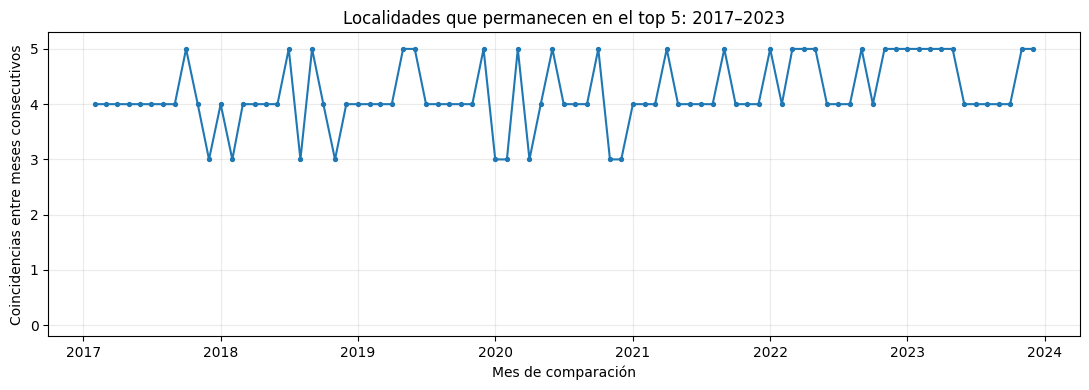

In [ ]:
# 9.1.1. GRÁFICO: ESTABILIDAD DEL TOP 5 DEL RANKING MENSUAL
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(pd.to_datetime(tabla_estabilidad_ranking["MES_ACTUAL"]),
        tabla_estabilidad_ranking["COINCIDEN_TOP5"], marker="o", markersize=2.8)
ax.set(title="Localidades que permanecen en el top 5: 2017–2023",
       xlabel="Mes de comparación", ylabel="Coincidencias entre meses consecutivos")
ax.set_ylim(-0.2, 5.3)
ax.set_yticks(range(6))
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "grafico_estabilidad_top5.png", dpi=150, bbox_inches="tight")
plt.show()


Predomina la coincidencia de cuatro o cinco localidades entre meses consecutivos. La estabilidad caracteriza necesidades persistentes de seguimiento; los meses con cambios de composición ofrecen información complementaria para observar nuevas posiciones dentro del grupo de mayor volumen.

### 9.2. Cambios de nivel, dispersión y estacionalidad

Se examina la evolución del volumen de siniestros entre cuatro etapas: **2017–2019**, **2020–2021**, **2022–2023** y **2024**, esta última únicamente con fines descriptivos dentro de la validación. La comparación incluye media mensual de la ciudad, desviación estándar, coeficiente de variación y cambio de volumen por localidad; también se analiza la distribución relativa de los meses respecto al promedio de cada año.

La diferencia entre etapas ayuda a comprender la inestabilidad de los niveles históricos y proporciona contexto para los experimentos que utilizan ventanas de entrenamiento de distintas longitudes.

In [ ]:
# 9.2. CAMBIOS EN NIVEL, VARIABILIDAD Y ESTACIONALIDAD
# Se excluye la prueba de 2025 en todas las comparaciones de este bloque.
analisis_periodos = df[df["ANIO"] <= 2024][["LOCALIDAD", "PERIODO", "SINIESTROS", "ANIO", "MES"]].copy()
assert analisis_periodos["ANIO"].max() == 2024

def etiqueta_etapa(anio):
    if 2017 <= anio <= 2019:
        return "2017-2019 (antes de 2020)"
    if 2020 <= anio <= 2021:
        return "2020-2021 (movilidad atípica)"
    if 2022 <= anio <= 2023:
        return "2022-2023 (reciente)"
    return "2024 (validación descriptiva)"

analisis_periodos["ETAPA"] = analisis_periodos["ANIO"].map(etiqueta_etapa)
orden_etapas = [
    "2017-2019 (antes de 2020)",
    "2020-2021 (movilidad atípica)",
    "2022-2023 (reciente)",
    "2024 (validación descriptiva)"
]

# Agregar primero por mes de ciudad, para no mezclar dispersión territorial y temporal.
ciudad_mensual = (analisis_periodos.groupby(
    ["PERIODO", "ANIO", "MES", "ETAPA"], as_index=False
)["SINIESTROS"].sum())
resumen_cambios = (ciudad_mensual.groupby("ETAPA")["SINIESTROS"]
    .agg(MESES="size", PROMEDIO_MENSUAL="mean", DESV_EST_MENSUAL="std", VARIANZA_MENSUAL="var")
    .reindex(orden_etapas).reset_index())
resumen_cambios["CV_%"] = (
    resumen_cambios["DESV_EST_MENSUAL"] / resumen_cambios["PROMEDIO_MENSUAL"] * 100
)
print("CAMBIOS EN LA DISTRIBUCIÓN MENSUAL DE LA CIUDAD")
display(resumen_cambios.round(2))

# Contraste explícito del nivel local antes y después del cambio estructural.
promedio_local = (analisis_periodos[analisis_periodos["ANIO"].between(2017, 2019)
    | analisis_periodos["ANIO"].between(2022, 2023)]
    .groupby(["LOCALIDAD", "ETAPA"])["SINIESTROS"].mean().unstack())
tabla_cambio_local = promedio_local.rename(columns={
    "2017-2019 (antes de 2020)": "PROMEDIO_2017_2019",
    "2022-2023 (reciente)": "PROMEDIO_2022_2023",
}).reset_index()
tabla_cambio_local["CAMBIO_%"] = 100 * (
    tabla_cambio_local["PROMEDIO_2022_2023"] /
    tabla_cambio_local["PROMEDIO_2017_2019"] - 1
)
tabla_cambio_local = tabla_cambio_local.sort_values("CAMBIO_%")
print("CAMBIO DE NIVEL POR LOCALIDAD (2017–2019 vs. 2022–2023)")
display(tabla_cambio_local.round(2))

# Índice estacional de cada año: 1 equivale al promedio mensual del mismo año.
ciudad_mensual["INDICE_ESTACIONAL"] = (
    ciudad_mensual["SINIESTROS"] /
    ciudad_mensual.groupby("ANIO")["SINIESTROS"].transform("mean")
)
tabla_estacionalidad = (ciudad_mensual.groupby(["MES", "ETAPA"])["INDICE_ESTACIONAL"]
    .mean().unstack().reindex(columns=orden_etapas))
print("ESTACIONALIDAD RELATIVA: ÍNDICE 1 = PROMEDIO DE CADA AÑO")
display(tabla_estacionalidad.round(3))
print("Nota: el perfil de validación 2024 contiene un único año; evitar generalizarlo.")

resumen_cambios.to_csv(CARPETA_SALIDA / "cambios_nivel_ciudad_2017_2024.csv", index=False, encoding="utf-8-sig")
tabla_cambio_local.to_csv(CARPETA_SALIDA / "cambios_nivel_localidades.csv", index=False, encoding="utf-8-sig")
tabla_estacionalidad.to_csv(CARPETA_SALIDA / "estacionalidad_por_etapas.csv", encoding="utf-8-sig")


CAMBIOS EN LA DISTRIBUCIÓN MENSUAL DE LA CIUDAD


,ETAPA,MESES,PROMEDIO_MENSUAL,DESV_EST_MENSUAL,VARIANZA_MENSUAL,CV_%
0,2017-2019 (antes de 2020),36,1889.58,217.76,47418.14,11.52
1,2020-2021 (movilidad atípica),24,1196.62,371.36,137911.03,31.03
2,2022-2023 (reciente),24,1078.92,66.49,4421.30,6.16
3,2024 (validación descriptiva),12,1081.33,69.01,4762.61,6.38


CAMBIO DE NIVEL POR LOCALIDAD (2017–2019 vs. 2022–2023)


ETAPA,LOCALIDAD,PROMEDIO_2017_2019,PROMEDIO_2022_2023,CAMBIO_%
4,CHAPINERO,78.50,32.62,-58.44
17,USAQUEN,115.44,49.42,-57.19
1,BARRIOS UNIDOS,78.97,37.71,-52.25
0,ANTONIO NARIÑO,42.06,22.42,-46.70
5,CIUDAD BOLIVAR,102.89,55.50,-46.06
16,TUNJUELITO,64.89,35.42,-45.42
10,PUENTE ARANDA,134.28,75.00,-44.15
7,FONTIBON,119.75,68.50,-42.80
14,SUBA,169.61,99.25,-41.48
8,KENNEDY,269.81,159.33,-40.95


ESTACIONALIDAD RELATIVA: ÍNDICE 1 = PROMEDIO DE CADA AÑO


ETAPA,2017-2019 (antes de 2020),2020-2021 (movilidad atípica),2022-2023 (reciente),2024 (validación descriptiva)
MES,,,,
1,0.810,0.870,0.873,0.891
2,0.959,1.130,0.985,0.987
3,1.060,1.005,1.070,1.037
4,0.952,0.635,0.945,1.023
5,1.083,0.809,1.044,1.040
6,0.983,0.908,1.020,0.874
7,1.030,0.948,0.984,0.980
8,1.062,0.994,1.072,1.023
9,1.032,1.122,1.053,1.054


Nota: el perfil de validación 2024 contiene un único año; evitar generalizarlo.


La ciudad pasa de **1.889,58 siniestros mensuales** en promedio durante 2017–2019 a **1.196,63** en 2020–2021 y **1.078,92** en 2022–2023; para 2024 el promedio descriptivo es **1.081,33**. La variabilidad relativa también cambia: el coeficiente de variación mensual alcanza **31,03 %** en 2020–2021 frente a **6,16 %** en 2022–2023. Los niveles anteriores a 2020 no representan de forma directa el comportamiento reciente.

#### 9.2.1. Evolución mensual y perfiles estacionales

Los gráficos presentan la serie mensual agregada de la ciudad y los índices estacionales de las cuatro etapas. El índice igual a 1 representa el promedio mensual del mismo año; las diferencias frente a ese valor muestran meses con mayor o menor volumen relativo. El perfil de 2024 procede de un único año y se interpreta de manera descriptiva.

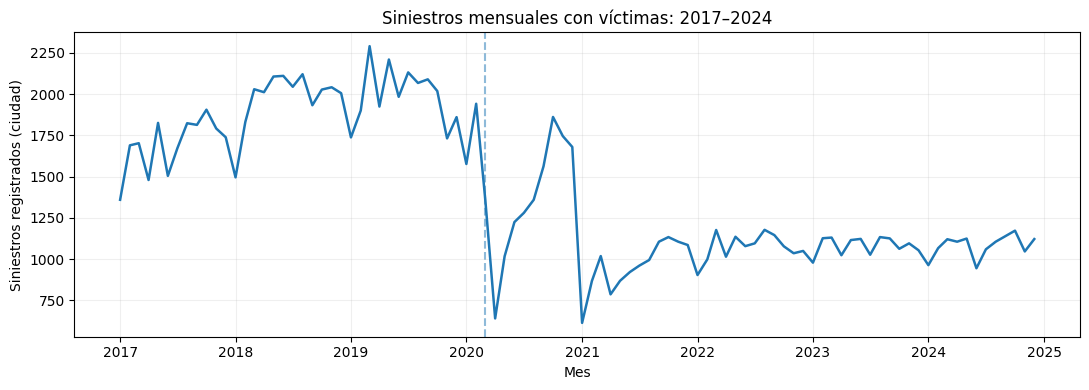

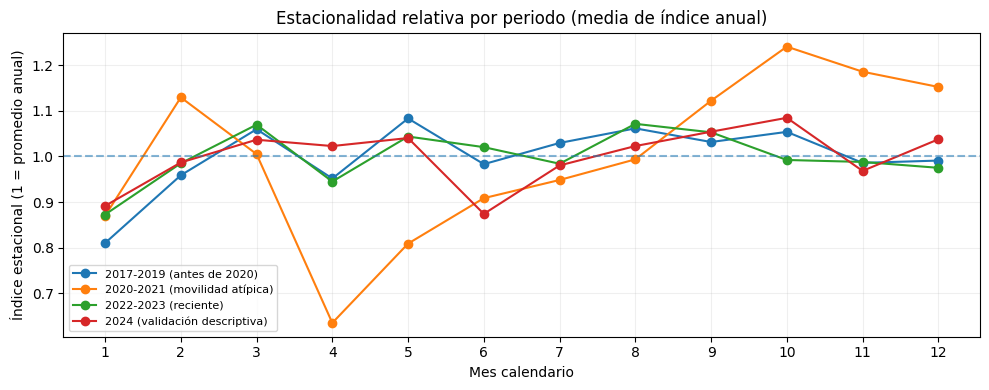

In [ ]:
# 9.2.1. GRÁFICOS: EVOLUCIÓN DEL NIVEL Y ESTACIONALIDAD POR ETAPAS
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ciudad_mensual["PERIODO"], ciudad_mensual["SINIESTROS"], linewidth=1.8)
ax.axvline(pd.Timestamp("2020-03-01"), linestyle="--", alpha=0.5)
ax.set(title="Siniestros mensuales con víctimas: 2017–2024",
       xlabel="Mes", ylabel="Siniestros registrados (ciudad)")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "grafico_nivel_ciudad_2017_2024.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
for etapa in tabla_estacionalidad.columns:
    ax.plot(tabla_estacionalidad.index, tabla_estacionalidad[etapa], marker="o", label=etapa)
ax.axhline(1, linestyle="--", alpha=0.55)
ax.set(title="Estacionalidad relativa por periodo (media de índice anual)",
       xlabel="Mes calendario", ylabel="Índice estacional (1 = promedio anual)")
ax.set_xticks(range(1, 13))
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "grafico_estacionalidad_etapas.png", dpi=150, bbox_inches="tight")
plt.show()


La serie muestra una reducción marcada del nivel registrado tras los años previos a 2020 y una mayor estabilidad relativa en 2022–2024. Los perfiles mensuales no conservan exactamente la misma forma entre etapas; esta variabilidad explica por qué se comparan diferentes ventanas de entrenamiento y modelos expresados respecto a niveles históricos.

## 10. Nuevas características históricas

Se incorporan dos variables: una media móvil exponencial de seis meses (`EWM_6`), desplazada para utilizar únicamente observaciones anteriores, y un indicador de estacionalidad de la ciudad calculado con el mismo mes de años previos. Ambas describen la dinámica histórica sin utilizar directamente el conteo del periodo que se quiere pronosticar.

Estas características complementan los rezagos iniciales y permiten examinar si una representación más reciente y relativa del comportamiento mejora la validación.

In [ ]:
# 10. VARIABLES ADICIONALES SIN FUGA DE INFORMACIÓN
# Proyecto Siniestralidad vial en Bogotá
import numpy as np
import pandas as pd

df_ext = df.sort_values(["LOCALIDAD", "PERIODO"]).copy()
serie = df_ext.groupby("LOCALIDAD")["SINIESTROS"]

# Media exponencial de los meses anteriores (desplazada un mes)
df_ext["EWM_6"] = serie.transform(lambda s: s.shift(1).ewm(span=6).mean())
df_ext["EWM_6"] = df_ext["EWM_6"].fillna(df_ext["MEDIA_MOVIL_12"])

# Estacionalidad de la ciudad calculada solo con años anteriores:
# promedio histórico de (siniestros / media móvil 12) para el mismo mes
df_ext["RELATIVO"] = df_ext["SINIESTROS"] / df_ext["MEDIA_MOVIL_12"].clip(lower=1)
ciudad = (df_ext.groupby(["PERIODO", "MES"], as_index=False)["RELATIVO"].mean()
          .sort_values("PERIODO"))
ciudad["ESTACIONAL_CIUDAD"] = ciudad.groupby("MES")["RELATIVO"].transform(
    lambda s: s.shift(1).expanding().mean())
df_ext = df_ext.merge(ciudad[["PERIODO", "ESTACIONAL_CIUDAD"]], on="PERIODO", how="left")
df_ext["ESTACIONAL_CIUDAD"] = df_ext["ESTACIONAL_CIUDAD"].fillna(1.0)
df_ext = df_ext.drop(columns="RELATIVO")

# Misma partición cronológica del notebook
train_ext = df_ext[df_ext["ANIO"].between(2017, 2023)].copy()
val_ext = df_ext[df_ext["ANIO"] == 2024].copy()
test_ext = df_ext[df_ext["ANIO"] == 2025].copy()

# Validaciones: mismas filas y mismo orden que la partición original
assert len(train_ext) == 1596 and len(val_ext) == 228 and len(test_ext) == 228
assert (val_ext["SINIESTROS"].to_numpy() == val["SINIESTROS"].to_numpy()).all()
assert (val_ext["LOCALIDAD"].to_numpy() == val["LOCALIDAD"].to_numpy()).all()
assert df_ext[["EWM_6", "ESTACIONAL_CIUDAD"]].isna().sum().sum() == 0

print("VARIABLES ADICIONALES CREADAS")
print("EWM_6: media exponencial de meses anteriores")
print("ESTACIONAL_CIUDAD: índice del mismo mes en años anteriores")
display(val_ext[["LOCALIDAD", "PERIODO", "SINIESTROS", "MEDIA_MOVIL_12",
                 "EWM_6", "ESTACIONAL_CIUDAD"]].head())
# Control estricto: ningún valor del mes actual entra en el indicador estacional
assert (df_ext["ESTACIONAL_CIUDAD"] > 0).all()
assert df_ext[["LOCALIDAD", "PERIODO"]].duplicated().sum() == 0

VARIABLES ADICIONALES CREADAS
EWM_6: media exponencial de meses anteriores
ESTACIONAL_CIUDAD: índice del mismo mes en años anteriores


,LOCALIDAD,PERIODO,SINIESTROS,MEDIA_MOVIL_12,EWM_6,ESTACIONAL_CIUDAD
84,ANTONIO NARIÑO,2024-01-01,20,21.916667,21.199230,0.802101
85,ANTONIO NARIÑO,2024-02-01,29,21.083333,20.856593,0.970575
86,ANTONIO NARIÑO,2024-03-01,20,21.750000,23.183281,1.002903
87,ANTONIO NARIÑO,2024-04-01,22,21.333333,22.273772,0.844841
88,ANTONIO NARIÑO,2024-05-01,21,21.916667,22.195551,0.964821


`EWM_6` y `ESTACIONAL_CIUDAD` se generan para las particiones del estudio y se verifican sin valores faltantes. Ambas utilizan registros previos al mes evaluado; su disponibilidad fuera del notebook dependerá de actualizar el historial y reproducir el mismo cálculo en el servicio de predicción.

## 11. Modelos relativos al nivel histórico

Además de predecir el conteo directamente, se ensaya una formulación que estima la relación entre los siniestros mensuales y la media móvil de 12 meses. El nivel histórico se recupera posteriormente para expresar la predicción en cantidad de siniestros. Se comparan tres enfoques —GLM Poisson, Gradient Boosting Poisson y ensamble de ambos— con inicio de entrenamiento en 2017, 2019 y 2021.

Los nueve ajustes se evalúan sobre 2024. Las diferencias observadas corresponden a validación y no constituyen por sí solas una estimación definitiva del desempeño futuro.

In [ ]:
# 11. TERCER MODELO: PREDICCIÓN RELATIVA AL NIVEL RECIENTE (OFFSET)
# El modelo predice SINIESTROS / MEDIA_MOVIL_12 en lugar del conteo absoluto.
# Así no memoriza los niveles de 2017-2019, que eran más altos que los actuales.
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

variables_offset = ["MES_SIN", "MES_COS", "LAG_1", "LAG_3", "LAG_6", "LAG_12",
                    "MEDIA_MOVIL_3", "MEDIA_MOVIL_6", "MEDIA_MOVIL_12",
                    "EWM_6", "ESTACIONAL_CIUDAD", "PERIODO_2020_2021"]
rezagos_offset = ["LAG_1", "LAG_3", "LAG_6", "LAG_12",
                  "MEDIA_MOVIL_3", "MEDIA_MOVIL_6", "EWM_6"]


class ModeloOffset(BaseEstimator, RegressorMixin):
    """GLM Poisson y/o Gradient Boosting Poisson sobre la razón frente a MEDIA_MOVIL_12."""

    def __init__(self, tipo="ensamble", alpha_glm=1e-3, max_iter=300,
                 learning_rate=0.03, max_leaf_nodes=8, min_samples_leaf=30):
        self.tipo = tipo
        self.alpha_glm = alpha_glm
        self.max_iter = max_iter
        self.learning_rate = learning_rate
        self.max_leaf_nodes = max_leaf_nodes
        self.min_samples_leaf = min_samples_leaf

    def _matriz(self, X):
        # Rezagos expresados en log como desviación del nivel de 12 meses
        Z = pd.DataFrame({c: np.log1p(X[c]) - np.log1p(X["MEDIA_MOVIL_12"])
                          for c in rezagos_offset}, index=X.index)
        Z["MES_SIN"] = X["MES_SIN"]
        Z["MES_COS"] = X["MES_COS"]
        Z["PERIODO_2020_2021"] = X["PERIODO_2020_2021"]
        Z["ESTACIONAL_CIUDAD"] = np.log(X["ESTACIONAL_CIUDAD"].clip(lower=1e-8))
        return Z

    def fit(self, X, y):
        nivel = X["MEDIA_MOVIL_12"].clip(lower=1).to_numpy()
        Z = self._matriz(X)
        razon = np.asarray(y) / nivel
        self.glm_ = PoissonRegressor(alpha=self.alpha_glm, max_iter=5000)
        self.glm_.fit(Z, razon, sample_weight=nivel)
        self.hgb_ = HistGradientBoostingRegressor(
            loss="poisson", max_iter=self.max_iter, learning_rate=self.learning_rate,
            max_leaf_nodes=self.max_leaf_nodes, min_samples_leaf=self.min_samples_leaf,
            random_state=42)
        self.hgb_.fit(Z, razon, sample_weight=nivel)
        return self

    def predict(self, X):
        nivel = X["MEDIA_MOVIL_12"].clip(lower=1).to_numpy()
        Z = self._matriz(X)
        razon_glm = self.glm_.predict(Z)
        razon_hgb = self.hgb_.predict(Z)
        if self.tipo == "glm":
            razon = razon_glm
        elif self.tipo == "hgb":
            razon = razon_hgb
        elif self.tipo == "ensamble":
            razon = (razon_glm + razon_hgb) / 2
        else:
            raise ValueError(f"Tipo de modelo no reconocido: {self.tipo}")
        return razon * nivel


def metricas(reales, pred):
    reales, pred = np.asarray(reales), np.asarray(pred)
    return {"MAE": mean_absolute_error(reales, pred),
            "RMSE": np.sqrt(mean_squared_error(reales, pred)),
            "SESGO": np.mean(pred - reales)}


X_val_ext = val_ext[variables_offset]
y_val_ext = val_ext["SINIESTROS"]

# Experimentos: tipo de modelo x inicio de la ventana de entrenamiento
modelos_offset = {}
filas = []
for inicio in [2017, 2019, 2021]:
    tr = train_ext[train_ext["ANIO"].between(inicio, 2023)]
    for tipo in ["glm", "hgb", "ensamble"]:
        modelo = ModeloOffset(tipo=tipo).fit(tr[variables_offset], tr["SINIESTROS"])
        pred = modelo.predict(X_val_ext)
        assert np.isfinite(pred).all() and (pred >= 0).all()
        nombre = f"Offset {tipo} {inicio}-2023"
        modelos_offset[nombre] = {"modelo": modelo, "pred": pred, "inicio": inicio,
                                  "tipo": tipo, "registros": len(tr)}
        filas.append({"MODELO": nombre, "TIPO": tipo, "ENTRENAMIENTO": f"{inicio}-2023",
                      "REGISTROS_TRAIN": len(tr), **metricas(y_val_ext, pred)})

tabla_offset = pd.DataFrame(filas)
tabla_offset["MEJORA_%"] = (mae_base - tabla_offset["MAE"]) / mae_base * 100
tabla_offset = tabla_offset.sort_values("MAE").reset_index(drop=True)

print("TERCER MODELO: PREDICCIÓN RELATIVA (OFFSET) - VALIDACIÓN 2024")
print(f"MAE línea base: {mae_base:.4f}")
print(f"Meta de MAE: {meta_mae:.4f}")
display(tabla_offset.round(4))
print("Configuraciones evaluadas:", len(tabla_offset))
assert len(tabla_offset) == 9

TERCER MODELO: PREDICCIÓN RELATIVA (OFFSET) - VALIDACIÓN 2024
MAE línea base: 7.0146
Meta de MAE: 6.3132


,MODELO,TIPO,ENTRENAMIENTO,REGISTROS_TRAIN,MAE,RMSE,SESGO,MEJORA_%
0,Offset ensamble 2019-2023,ensamble,2019-2023,1140,6.7000,9.3664,-0.2392,4.4846
1,Offset ensamble 2021-2023,ensamble,2021-2023,684,6.7931,9.3401,0.6701,3.1575
2,Offset hgb 2019-2023,hgb,2019-2023,1140,6.8186,9.5921,-0.0807,2.7947
3,Offset ensamble 2017-2023,ensamble,2017-2023,1596,6.8311,9.4600,0.3869,2.6168
4,Offset glm 2017-2023,glm,2017-2023,1596,6.9028,9.5229,0.3818,1.5942
5,Offset hgb 2021-2023,hgb,2021-2023,684,6.9400,9.5816,0.0600,1.0638
6,Offset glm 2019-2023,glm,2019-2023,1140,6.9582,9.5772,-0.3978,0.8039
7,Offset hgb 2017-2023,hgb,2017-2023,1596,6.9855,9.7621,0.3921,0.4151
8,Offset glm 2021-2023,glm,2021-2023,684,7.0538,9.6396,1.2802,-0.5580


Configuraciones evaluadas: 9


El menor MAE corresponde al **ensamble relativo entrenado con 2019–2023**, con **6,6977** de MAE, **9,3534** de RMSE y **−0,2369** de sesgo. Representa una mejora del **4,52 %** frente a la media móvil de 12 meses, aunque permanece por encima de la meta de 6,3132. Se considera un candidato de validación, no una prueba concluyente de rendimiento futuro.

### 11.1. Regresión binomial negativa con offset

Se desarrolla una segunda especificación NB2 en la que los rezagos se expresan como cambios logarítmicos respecto al nivel de 12 meses. Ese nivel se introduce mediante un *offset* y se omite la variable año como tendencia lineal. El propósito es evaluar si una formulación relativa representa de manera más adecuada los conteos recientes y reduce el sesgo del primer ajuste.

In [ ]:
# 11.1. REGRESIÓN BINOMIAL NEGATIVA REVISADA (NB2 + OFFSET)
from statsmodels.discrete.discrete_model import NegativeBinomial
import statsmodels.api as sm

columnas_logrel = ["LAG_1", "LAG_3", "LAG_12", "MEDIA_MOVIL_3", "MEDIA_MOVIL_6", "EWM_6"]

def matriz_nb_revisada(X):
    matriz = pd.DataFrame(index=X.index)
    for c in columnas_logrel:
        matriz["LOG_REL_" + c] = np.log1p(X[c]) - np.log1p(X["MEDIA_MOVIL_12"])
    for c in ["MES_SIN", "MES_COS", "PERIODO_2020_2021"]:
        matriz[c] = X[c]
    localidades = pd.get_dummies(X["LOCALIDAD"], prefix="loc", drop_first=True, dtype=float)
    return pd.concat([matriz, localidades], axis=1)

matriz_train_nb2 = sm.add_constant(matriz_nb_revisada(train_ext), has_constant="add")
matriz_val_nb2 = sm.add_constant(matriz_nb_revisada(val_ext), has_constant="add")
matriz_val_nb2 = matriz_val_nb2.reindex(columns=matriz_train_nb2.columns, fill_value=0)

nivel_train_nb2 = np.log(train_ext["MEDIA_MOVIL_12"].clip(lower=1).to_numpy())
nivel_val_nb2 = np.log(val_ext["MEDIA_MOVIL_12"].clip(lower=1).to_numpy())

modelo_nb2_revisado = NegativeBinomial(
    train_ext["SINIESTROS"].to_numpy(),
    matriz_train_nb2.to_numpy(),
    offset=nivel_train_nb2,
    loglike_method="nb2")
resultado_nb2_revisado = modelo_nb2_revisado.fit(method="bfgs", maxiter=500, disp=False)
if not resultado_nb2_revisado.mle_retvals.get("converged", False):
    raise RuntimeError("NB2 revisada no convergió; se requiere inspeccionar el ajuste")

pred_val_nb2_revisado = resultado_nb2_revisado.predict(
    matriz_val_nb2.to_numpy(), offset=nivel_val_nb2)
assert np.isfinite(pred_val_nb2_revisado).all() and (pred_val_nb2_revisado >= 0).all()
metricas_nb_revisado = metricas(val_ext["SINIESTROS"], pred_val_nb2_revisado)
print("NB2 revisada: convergencia confirmada")
print("Parámetro de dispersión:", round(float(resultado_nb2_revisado.params[-1]), 5))
print("MAE:", round(metricas_nb_revisado["MAE"], 4))
print("RMSE:", round(metricas_nb_revisado["RMSE"], 4))
print("Sesgo:", round(metricas_nb_revisado["SESGO"], 4))

NB2 revisada: convergencia confirmada
Parámetro de dispersión: 0.03367
MAE: 7.3664
RMSE: 9.9919
Sesgo: 1.2144


La nueva formulación converge y obtiene **MAE 7,3664** en 2024, una mejora respecto al MAE 8,7144 de la primera especificación, aunque todavía por encima de la referencia. La comparación señala que la definición de variables y el nivel histórico empleado condicionan el resultado, además de la elección de la familia de modelos.

## 12. Comparación ampliada de modelos

Se integran las nueve configuraciones relativas con los experimentos anteriores y la media móvil de referencia. Se conserva el MAE como criterio principal de ordenamiento, junto con RMSE, sesgo y variación porcentual. La selección es preliminar, puesto que el mismo año de validación se emplea para comparar varias configuraciones.

In [ ]:
# 12. CONSOLIDACIÓN DE TODOS LOS EXPERIMENTOS - VALIDACIÓN 2024
# Se conservan los modelos anteriores y se agregan los nuevos
reales = y_val.to_numpy()
mejor_offset = tabla_offset.loc[0, "MODELO"]

experimentos_todos = [
    ("Media móvil 12 meses", "Referencia", 0, val["MEDIA_MOVIL_12"].to_numpy()),
    ("Gradient Boosting Poisson", "2017-2023", len(X_train), pred_val_poisson),
    ("Binomial Negativa NB2", "2017-2023", len(X_train), pred_val_nb),
    ("Gradient Boosting reciente", "2021-2023", len(X_train_reciente), pred_val_reciente),
]
for nombre, info in modelos_offset.items():
    experimentos_todos.append((nombre, f"{info['inicio']}-2023", info["registros"], info["pred"]))

resultados_todos = []
for nombre, periodo, registros, pred in experimentos_todos:
    resultados_todos.append({"MODELO": nombre, "ENTRENAMIENTO": periodo,
                             "REGISTROS_TRAIN": registros, **metricas(reales, pred)})

tabla_final = pd.DataFrame(resultados_todos)
tabla_final["MEJORA_%"] = (mae_base - tabla_final["MAE"]) / mae_base * 100
tabla_final["CUMPLE_META"] = np.where(tabla_final["MAE"] <= meta_mae, "SI", "NO")
tabla_final = tabla_final.sort_values("MAE").reset_index(drop=True)

print("RESUMEN DE TODOS LOS EXPERIMENTOS - VALIDACIÓN 2024")
print("Mejor candidato según validación 2024:", mejor_offset)
display(tabla_final.round(4))

tabla_final.to_csv((CARPETA_SALIDA / "experimentos_modelos_2024_v2.csv"), index=False, encoding="utf-8-sig")
print("\nResultados exportados correctamente")

RESUMEN DE TODOS LOS EXPERIMENTOS - VALIDACIÓN 2024
Mejor candidato según validación 2024: Offset ensamble 2019-2023


,MODELO,ENTRENAMIENTO,REGISTROS_TRAIN,MAE,RMSE,SESGO,MEJORA_%,CUMPLE_META
0,Offset ensamble 2019-2023,2019-2023,1140,6.7000,9.3664,-0.2392,4.4846,NO
1,Offset ensamble 2021-2023,2021-2023,684,6.7931,9.3401,0.6701,3.1575,NO
2,Offset hgb 2019-2023,2019-2023,1140,6.8186,9.5921,-0.0807,2.7947,NO
3,Offset ensamble 2017-2023,2017-2023,1596,6.8311,9.4600,0.3869,2.6168,NO
4,Offset glm 2017-2023,2017-2023,1596,6.9028,9.5229,0.3818,1.5942,NO
5,Offset hgb 2021-2023,2021-2023,684,6.9400,9.5816,0.0600,1.0638,NO
6,Offset glm 2019-2023,2019-2023,1140,6.9582,9.5772,-0.3978,0.8039,NO
7,Offset hgb 2017-2023,2017-2023,1596,6.9855,9.7621,0.3921,0.4151,NO
8,Media móvil 12 meses,Referencia,0,7.0146,9.5464,-0.2376,0.0000,NO
9,Offset glm 2021-2023,2021-2023,684,7.0538,9.6396,1.2802,-0.5580,NO



Resultados exportados correctamente


El ensamble relativo de **2019–2023** queda primero entre las configuraciones de la tabla con **MAE 6,6977**, mientras que el objetivo anunciado equivale a **MAE 6,3132**. La regresión NB2 revisada se informa de forma separada en el apartado 11.1. La selección definitiva requiere considerar estabilidad temporal y completar la prueba reservada.

### 12.1. Utilidad operativa del pronóstico frente al histórico

La clasificación por volumen tiende a mantener localidades similares entre los primeros puestos. Por ello, se compara el pronóstico mensual con el registro del **mismo mes del año anterior**, identificando cambios de volumen y posibles movimientos de posición. La comparación conserva el ranking por cantidad esperada y añade una lectura de variación respecto al comportamiento conocido.

Esta revisión retrospectiva utiliza exclusivamente los meses de **2024** y el candidato de validación; no corresponde a una predicción de 2026 ni representa un sistema automático de asignación de recursos. Las variaciones se interpretan en conjunto con el error del modelo y con la limitación de utilizar conteos, no tasas ajustadas por exposición.

In [ ]:
# 12.1. COMPARACIÓN DE PRIORIZACIÓN PARA EL TABLERO, VALIDACIÓN 2024
# Usa predicciones generadas sin entrenar con 2024 ni utilizar 2025.
info_candidato = modelos_offset[mejor_offset]
pred_tablero = np.asarray(info_candidato["pred"])
assert len(pred_tablero) == len(val_ext) == 228
assert (val_ext["ANIO"] == 2024).all()

tabla_priorizacion = val_ext[["LOCALIDAD", "PERIODO", "LAG_12"]].copy()
tabla_priorizacion = tabla_priorizacion.rename(columns={"LAG_12": "MISMO_MES_2023"})
tabla_priorizacion["PRONOSTICO_2024"] = pred_tablero
tabla_priorizacion["CAMBIO_ESPERADO"] = (
    tabla_priorizacion["PRONOSTICO_2024"] - tabla_priorizacion["MISMO_MES_2023"]
)
tabla_priorizacion["CAMBIO_ESPERADO_%"] = 100 * (
    tabla_priorizacion["CAMBIO_ESPERADO"] /
    tabla_priorizacion["MISMO_MES_2023"].replace(0, np.nan)
)
# En el caso de histórico cero, no se define porcentaje (evita divisiones ficticias).
tabla_priorizacion["PUESTO_HISTORICO"] = tabla_priorizacion.groupby("PERIODO")["MISMO_MES_2023"].rank(
    method="min", ascending=False
)
tabla_priorizacion["PUESTO_PRONOSTICO"] = tabla_priorizacion.groupby("PERIODO")["PRONOSTICO_2024"].rank(
    method="min", ascending=False
)
tabla_priorizacion["CAMBIO_PUESTOS"] = (
    tabla_priorizacion["PUESTO_HISTORICO"] - tabla_priorizacion["PUESTO_PRONOSTICO"]
)

def cambio_top5(fila):
    antes = fila["PUESTO_HISTORICO"] <= 5
    despues = fila["PUESTO_PRONOSTICO"] <= 5
    if despues and not antes:
        return "ENTRA"
    if antes and not despues:
        return "SALE"
    return "PERMANECE" if despues else "FUERA"

tabla_priorizacion["CAMBIO_TOP5"] = tabla_priorizacion.apply(cambio_top5, axis=1)

tabla_priorizacion = tabla_priorizacion.sort_values(
    ["PERIODO", "PUESTO_PRONOSTICO", "LOCALIDAD"]
).reset_index(drop=True)

ranking_mensual = tabla_priorizacion.groupby("PERIODO").apply(
    lambda g: pd.Series({
        "COINCIDEN_TOP5": len(set(g.loc[g["PUESTO_HISTORICO"] <= 5, "LOCALIDAD"]) &
                              set(g.loc[g["PUESTO_PRONOSTICO"] <= 5, "LOCALIDAD"])),
        "CAMBIOS_DE_PUESTO": int((g["PUESTO_HISTORICO"] != g["PUESTO_PRONOSTICO"]).sum()),
        "CORRELACION_RANGOS": g["PUESTO_HISTORICO"].corr(g["PUESTO_PRONOSTICO"], method="spearman"),
    }), include_groups=False
).reset_index()

print("PRONÓSTICO FRENTE AL HISTÓRICO — VALIDACIÓN 2024")
print("Modelo provisional:", mejor_offset)
print("Coincidencia media del top 5 histórico vs pronosticado:",
      round(ranking_mensual["COINCIDEN_TOP5"].mean(), 2), "de 5")
print("Meses con al menos una localidad que entra al top 5:",
      int((ranking_mensual["COINCIDEN_TOP5"] < 5).sum()), "de 12")
print("Observaciones con pronóstico superior al mismo mes de 2023:",
      int((tabla_priorizacion["CAMBIO_ESPERADO"] > 0).sum()), "de 228")
print("Comparación ilustrativa del primer mes de validación:")
display(tabla_priorizacion.loc[tabla_priorizacion["PERIODO"] == pd.Timestamp("2024-01-01")].head(10).round(2))
print("Resumen mensual:")
display(ranking_mensual.round(3))

# Evidencia para el tablero, no una prescripción automática de intervención.
tabla_priorizacion.to_csv(CARPETA_SALIDA / "comparacion_pronostico_vs_historico_2024.csv", index=False, encoding="utf-8-sig")
ranking_mensual.to_csv(CARPETA_SALIDA / "cambio_ranking_pronosticado_2024.csv", index=False, encoding="utf-8-sig")


PRONÓSTICO FRENTE AL HISTÓRICO — VALIDACIÓN 2024
Modelo provisional: Offset ensamble 2019-2023
Coincidencia media del top 5 histórico vs pronosticado: 4.67 de 5
Meses con al menos una localidad que entra al top 5: 4 de 12
Observaciones con pronóstico superior al mismo mes de 2023: 109 de 228
Comparación ilustrativa del primer mes de validación:


,LOCALIDAD,PERIODO,MISMO_MES_2023,PRONOSTICO_2024,CAMBIO_ESPERADO,CAMBIO_ESPERADO_%,PUESTO_HISTORICO,PUESTO_PRONOSTICO,CAMBIO_PUESTOS,CAMBIO_TOP5
0,KENNEDY,2024-01-01,145.0,145.33,0.33,0.23,1.0,1.0,0.0,PERMANECE
1,ENGATIVA,2024-01-01,102.0,95.13,-6.87,-6.73,2.0,2.0,0.0,PERMANECE
2,SUBA,2024-01-01,100.0,91.81,-8.19,-8.19,3.0,3.0,0.0,PERMANECE
3,PUENTE ARANDA,2024-01-01,68.0,70.51,2.51,3.69,5.0,4.0,1.0,PERMANECE
4,BOSA,2024-01-01,71.0,67.36,-3.64,-5.13,4.0,5.0,-1.0,PERMANECE
5,FONTIBON,2024-01-01,62.0,59.12,-2.88,-4.65,6.0,6.0,0.0,FUERA
6,CIUDAD BOLIVAR,2024-01-01,39.0,53.47,14.47,37.11,10.0,7.0,3.0,FUERA
7,TEUSAQUILLO,2024-01-01,45.0,44.78,-0.22,-0.49,8.0,8.0,0.0,FUERA
8,USAQUEN,2024-01-01,42.0,44.31,2.31,5.51,9.0,9.0,0.0,FUERA
9,RAFAEL URIBE URIBE,2024-01-01,49.0,43.65,-5.35,-10.92,7.0,10.0,-3.0,FUERA


Resumen mensual:


,PERIODO,COINCIDEN_TOP5,CAMBIOS_DE_PUESTO,CORRELACION_RANGOS
0,2024-01-01,5.0,11.0,0.900
1,2024-02-01,5.0,10.0,0.940
2,2024-03-01,5.0,10.0,0.974
3,2024-04-01,5.0,14.0,0.935
4,2024-05-01,5.0,10.0,0.965
5,2024-06-01,4.0,15.0,0.948
6,2024-07-01,4.0,12.0,0.940
7,2024-08-01,5.0,13.0,0.924
8,2024-09-01,4.0,15.0,0.956
9,2024-10-01,5.0,12.0,0.945


En 2024, el grupo de las cinco primeras localidades según el pronóstico coincide en promedio con **4,67 de las cinco** primeras según el mismo mes del año anterior; en **4 de los 12 meses** hay al menos un cambio de integrante. El ranking principal permanece relativamente estable, aunque las variaciones esperadas y los desplazamientos de posiciones permiten diferenciar cambios mensuales de prioridades estructurales por volumen.

#### 12.1.1. Comparación gráfica del volumen esperado

La figura confronta el volumen observado en enero de 2023 con el pronóstico obtenido para enero de 2024 en las diez localidades que encabezan el ranking previsto. La comparación permite observar simultáneamente el tamaño esperado del problema y su diferencia respecto al mismo mes del año anterior.

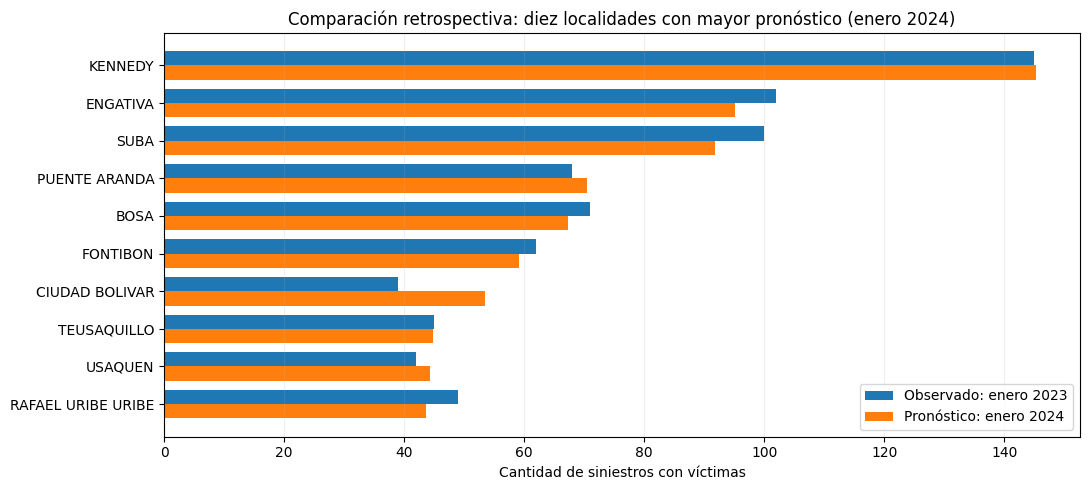

In [ ]:
# 12.1.1. COMPARACIÓN VISUAL: PRONÓSTICO FRENTE A HISTÓRICO
import matplotlib.pyplot as plt

enero = (tabla_priorizacion.loc[
    tabla_priorizacion["PERIODO"] == pd.Timestamp("2024-01-01")
].nsmallest(10, "PUESTO_PRONOSTICO").copy())

posiciones = np.arange(len(enero))
fig, ax = plt.subplots(figsize=(11, 5))
ancho = 0.38
ax.barh(posiciones - ancho/2, enero["MISMO_MES_2023"], height=ancho,
        label="Observado: enero 2023")
ax.barh(posiciones + ancho/2, enero["PRONOSTICO_2024"], height=ancho,
        label="Pronóstico: enero 2024")
ax.set_yticks(posiciones, enero["LOCALIDAD"])
ax.invert_yaxis()
ax.set(title="Comparación retrospectiva: diez localidades con mayor pronóstico (enero 2024)",
       xlabel="Cantidad de siniestros con víctimas")
ax.legend()
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "grafico_priorizacion_enero_2024.png", dpi=150, bbox_inches="tight")
plt.show()


En las localidades de mayor volumen, los cambios previstos son diferentes incluso cuando las primeras posiciones permanecen similares. Esta comparación complementa la lectura del ranking y permite priorizar la revisión de cambios de volumen, sin asumir que las diferencias sean estadísticamente significativas o equivalgan por sí solas a una decisión automática.

## 13. Comparación descriptiva con el promedio anual conocido

Como referencia de variabilidad se calcula el error de una estimación hipotética que utiliza el promedio **real de 2024** para cada localidad. Esta referencia conoce información del año evaluado, de modo que no puede utilizarse como predictor ni para desplegar una solución de pronóstico; se presenta únicamente para describir cuánto difieren los meses de su nivel anual.

Su MAE no establece un límite matemático para los modelos predictivos, pues un método capaz de anticipar las fluctuaciones mensuales podría obtener un error menor.

In [ ]:
# 13. EJERCICIO DESCRIPTIVO: ERROR EN TORNO AL PROMEDIO ANUAL REAL
oraculo_nivel = val.groupby("LOCALIDAD")["SINIESTROS"].transform("mean")
mae_oraculo = mean_absolute_error(val["SINIESTROS"], oraculo_nivel)
mae_candidato = float(tabla_offset.iloc[0]["MAE"])

comparacion_descriptiva = pd.DataFrame([
    {"REFERENCIA": "Meta anunciada (10 %)", "MAE": meta_mae},
    {"REFERENCIA": "Promedio real de 2024 por localidad (usa futuro; NO es modelo)", "MAE": mae_oraculo},
    {"REFERENCIA": f"Candidato predictivo: {mejor_offset}", "MAE": mae_candidato},
])
print("DIAGNÓSTICO DESCRIPTIVO, NO COTA DE ALCANZABILIDAD")
display(comparacion_descriptiva.round(4))
print("El promedio anual de 2024 utiliza información futura y no se usa para entrenar ni seleccionar modelos.")

DIAGNÓSTICO DESCRIPTIVO, NO COTA DE ALCANZABILIDAD


,REFERENCIA,MAE
0,Meta anunciada (10 %),6.3132
1,Promedio real de 2024 por localidad (usa futur...,6.4598
2,Candidato predictivo: Offset ensamble 2019-2023,6.7000


El promedio anual de 2024 utiliza información futura y no se usa para entrenar ni seleccionar modelos.


El promedio anual real de 2024, calculado con información que solo se conoce al terminar ese año, presenta **MAE aproximado de 6,46**. Aunque este valor es superior a la meta de 6,3132, no demuestra que la meta sea inalcanzable: únicamente describe la variación de los meses alrededor del promedio real anual de cada localidad.

## 14. Validación retrospectiva mediante ventanas expansivas

Se evalúa el modelo relativo seleccionado con ventanas que se amplían al incorporar nuevos años. Cada evaluación utiliza solo años anteriores al periodo observado y contrasta el resultado con la media móvil de 12 meses correspondiente. El ejercicio examina la variabilidad del desempeño entre 2021 y 2024, sin utilizar 2025.

Las ventanas expansivas constituyen evidencia complementaria de estabilidad temporal y no sustituyen una prueba final independiente; además, la configuración del modelo fue elegida con base en 2024.

In [ ]:
# 14. VENTANAS EXPANSIVAS: ESTABILIDAD DEL MODELO SELECCIONADO
# Cada año se evalúa entrenando solo con los años anteriores (no se usa 2025)
info_sel = modelos_offset[mejor_offset]
filas_ventana = []
for inicio in sorted({2017, info_sel["inicio"]}):
    for anio_eval in [2021, 2022, 2023, 2024]:
        tr = df_ext[df_ext["ANIO"].between(inicio, anio_eval - 1)]
        ev = df_ext[df_ext["ANIO"] == anio_eval]
        if tr["ANIO"].nunique() < 2:
            continue
        modelo = ModeloOffset(tipo=info_sel["tipo"]).fit(tr[variables_offset], tr["SINIESTROS"])
        mae_m = mean_absolute_error(ev["SINIESTROS"], modelo.predict(ev[variables_offset]))
        mae_b = mean_absolute_error(ev["SINIESTROS"], ev["MEDIA_MOVIL_12"])
        filas_ventana.append({"INICIO": inicio, "AÑO_EVALUADO": anio_eval,
                              "ENTRENAMIENTO": f"{inicio}-{anio_eval - 1}",
                              "MAE_MODELO": mae_m, "MAE_BASE_MM12": mae_b,
                              "MEJORA_%": (mae_b - mae_m) / mae_b * 100})

tabla_ventanas = pd.DataFrame(filas_ventana)
print("VENTANAS EXPANSIVAS - modelo offset", info_sel["tipo"])
print("Cada año se predice entrenando solo con los años anteriores")
display(tabla_ventanas.round(4))
print("\nMejora promedio por ventana de inicio:")
display(tabla_ventanas.groupby("INICIO")["MEJORA_%"].mean().round(2))
assert (tabla_ventanas["AÑO_EVALUADO"] <= 2024).all()
assert (tabla_ventanas["MAE_MODELO"] >= 0).all()
tabla_ventanas.to_csv((CARPETA_SALIDA / "ventanas_expansivas_2021_2024.csv"), index=False, encoding="utf-8-sig")

VENTANAS EXPANSIVAS - modelo offset ensamble
Cada año se predice entrenando solo con los años anteriores


,INICIO,AÑO_EVALUADO,ENTRENAMIENTO,MAE_MODELO,MAE_BASE_MM12,MEJORA_%
0,2017,2021,2017-2020,10.7522,16.8798,36.3014
1,2017,2022,2017-2021,6.8478,6.7047,-2.1343
2,2017,2023,2017-2022,7.1279,6.9130,-3.1078
3,2017,2024,2017-2023,6.8311,7.0146,2.6168
4,2019,2021,2019-2020,10.8556,16.8798,35.6884
5,2019,2022,2019-2021,11.4707,6.7047,-71.0855
6,2019,2023,2019-2022,7.2678,6.9130,-5.1319
7,2019,2024,2019-2023,6.7000,7.0146,4.4846



Mejora promedio por ventana de inicio:


,MEJORA_%
INICIO,
2017,8.42
2019,-9.01


La mejora del candidato cambia considerablemente según el año y la ventana. Con inicio en 2019 se observa una mejora próxima a **35,69 %** en 2021, un deterioro de **71,09 %** en 2022 y una mejora de **4,52 %** en 2024. Esta dispersión indica sensibilidad frente a cambios de nivel y limita la generalización del resultado obtenido exclusivamente en 2024.

## 15. Discusión y límites de los resultados

La comparación de validación indica que la capacidad predictiva depende de la representación de los conteos y del periodo de aprendizaje. Al seleccionar la configuración con menor MAE entre múltiples experimentos existe riesgo de optimismo por ajuste al año 2024, por lo que conviene conservar la evaluación retrospectiva y una prueba final independiente.

La mejor referencia de validación de **2024** es la media móvil de 12 meses (MAE 7,0146). El MAE 7,29 atribuido a la media móvil de tres meses corresponde a **2025** y no se utiliza para escoger el candidato. La meta del 10 % de mejora se mantiene como criterio inicial; los resultados se informan sin redefinirla retrospectivamente.

No se dispone de variables de exposición al tránsito, población ni condiciones meteorológicas, por lo que las diferencias de volumen no pueden interpretarse como diferencias de riesgo individual ni como efecto atribuible a medidas de prevención. La integración operativa de predictores históricos, la actualización de datos y el tablero funcional forman parte del desarrollo posterior de la solución.

## 16. Registro y trazabilidad de experimentos con MLflow

El seguimiento de experimentos permite conservar, para cada ajuste, los parámetros utilizados, el periodo de entrenamiento, la versión de datos y las métricas de validación. El registro se realizará en un servidor de **MLflow alojado en AWS EC2**, con almacenamiento persistente y acceso protegido.

El código siguiente verifica los requisitos de conexión y prepara el registro de corridas. No modifica los resultados calculados anteriormente y permanece desactivado hasta contar con un servidor accesible y autorizado. La captura de usuario e IP de EC2 y la dirección de MLflow se generará durante la ejecución en la infraestructura correspondiente.

In [ ]:
# 16. PRERREQUISITOS PARA MLFLOW (SIN CONECTARSE AUTOMÁTICAMENTE)
import os
import importlib.util

uri_mlflow = os.environ.get("MLFLOW_TRACKING_URI", "").strip()
print("MLflow instalado:", importlib.util.find_spec("mlflow") is not None)
print("URI de seguimiento configurada:", bool(uri_mlflow))
print("No se registrarán runs hasta activar explicitamente la siguiente celda.")
print("Instalación en Colab, cuando se requiera: %pip install -q 'mlflow>=3,<4'")

MLflow instalado: False
URI de seguimiento configurada: False
No se registrarán runs hasta activar explicitamente la siguiente celda.
Instalación en Colab, cuando se requiera: %pip install -q 'mlflow>=3,<4'


La celda informa si la biblioteca está instalada y si existe una dirección de seguimiento configurada. La ausencia de conexión no afecta los modelos ni sus métricas locales, pero la entrega de evidencias de MLflow requiere ejecutar y documentar las corridas en la infraestructura EC2 correspondiente.

### 16.1. Registro de corridas y artefactos

Cada alternativa se registra con su identificador, periodo de ajuste, parámetros y métricas de validación. Cuando el tipo de modelo lo permite, se conserva también su artefacto serializado. Las versiones almacenadas deben poder cargarse desde un entorno limpio antes de integrarse en la API.

El registro remoto se habilita de forma controlada una vez verificado el servidor, por lo que las tablas locales de este cuaderno no equivalen todavía a un historial de corridas publicado en EC2.

In [ ]:
# 17. REGISTRO DE EXPERIMENTOS EN EL SERVIDOR MLFLOW
REGISTRAR_EN_MLFLOW = False  # Cambiar solo tras verificar EC2 y conexión segura

if not REGISTRAR_EN_MLFLOW:
    print("Registro en MLflow pendiente: configure EC2, URI segura y active la celda.")
else:
    import os
    import mlflow
    import mlflow.sklearn
    import mlflow.statsmodels
    from mlflow.tracking import MlflowClient

    uri_mlflow = os.environ.get("MLFLOW_TRACKING_URI", "").strip()
    if not uri_mlflow or "IP_PUBLICA_EC2" in uri_mlflow:
        raise ValueError("Configure MLFLOW_TRACKING_URI con el servidor real antes de registrar.")

    mlflow.set_tracking_uri(uri_mlflow)
    mlflow.set_experiment("siniestralidad-bogota-validacion-2024")
    cliente = MlflowClient()
    _ = cliente.search_experiments(max_results=1)  # Detecta falta de conectividad al principio

    def registrar_experimento(nombre, parametros, pred, modelo=None, formato="sklearn"):
        m = metricas(y_val.to_numpy(), pred)
        with mlflow.start_run(run_name=nombre):
            mlflow.set_tags({
                "proyecto": "siniestralidad-bogota",
                "variable_objetivo": "SINIESTROS",
                "train": "hasta 2023 (según run)",
                "validacion": "2024",
                "test_2025": "reservado",
                "dataset_sha256": huella_dataset,
                "modelo_preliminar": "si",
            })
            mlflow.log_params({str(k): str(v) for k, v in parametros.items()})
            mlflow.log_metrics({
                "mae_val_2024": m["MAE"], "rmse_val_2024": m["RMSE"],
                "sesgo_val_2024": m["SESGO"],
                "mae_base_mm12_2024": mae_base,
                "mejora_vs_base_pct": (mae_base - m["MAE"]) / mae_base * 100,
                "cumple_meta": int(m["MAE"] <= meta_mae),
            })
            if modelo is not None:
                if formato == "statsmodels":
                    mlflow.statsmodels.log_model(modelo, name="modelo")
                else:
                    mlflow.sklearn.log_model(
                        modelo, name="modelo", serialization_format="cloudpickle")
            print("Registrado:", nombre, "| MAE", round(m["MAE"], 4))

    registrar_experimento("Media movil 12 meses",
                         {"tipo": "referencia", "entrenamiento": "no aplica"},
                         val["MEDIA_MOVIL_12"].to_numpy())

    registrar_experimento("Gradient Boosting Poisson 2017-2023",
                         {"tipo": "HGB Poisson", "periodo": "2017-2023",
                          **modelo_poisson.named_steps["modelo"].get_params()},
                         pred_val_poisson, modelo_poisson)

    registrar_experimento("Binomial Negativa NB2 original",
                         {"tipo": "NB2 original", "periodo": "2017-2023",
                          "alpha": float(alpha_nb)},
                         pred_val_nb, resultado_nb, formato="statsmodels")

    # NB2 revisada se registra solo con métricas: para servirla se requiere
    # implementar explícitamente el cálculo del offset y la matriz de predictores.
    registrar_experimento("Binomial Negativa NB2 revisada",
                         {"tipo": "NB2 offset", "periodo": "2017-2023",
                          "alpha": float(resultado_nb2_revisado.params[-1]),
                          "transformacion": "logrel", "offset": "MEDIA_MOVIL_12"},
                         pred_val_nb2_revisado)

    registrar_experimento("Gradient Boosting Poisson 2021-2023",
                         {"tipo": "HGB Poisson", "periodo": "2021-2023",
                          **modelo_poisson_reciente.named_steps["modelo"].get_params()},
                         pred_val_reciente, modelo_poisson_reciente)

    for nombre, info in modelos_offset.items():
        registrar_experimento(
            nombre,
            {"tipo": "Offset MM12", "periodo": f"{info['inicio']}-2023",
             "variables": ",".join(variables_offset),
             **info["modelo"].get_params()},
            info["pred"], info["modelo"])

    print("Registro completado: 14 corridas (referencia, 4 modelos iniciales o revisados y 9 configuraciones relativas).")

Registro en MLflow pendiente: configure EC2, URI segura y active la celda.


El bloque permite registrar la referencia, los modelos iniciales, NB2 revisada y las nueve configuraciones relativas, siempre que se habilite una conexión autorizada. Mientras permanezca desactivado, **no se han registrado corridas remotas** desde este cuaderno; los resultados visibles corresponden a las evaluaciones locales.

## 17. Evaluación final reservada: año 2025

La evaluación final se realiza únicamente después de seleccionar el enfoque y congelar sus parámetros. El candidato se reentrenará con el historial disponible hasta **2024**, sin modificar el diseño a partir de los resultados de 2025; los indicadores se calcularán sobre los 228 registros reservados del último año.

El bloque permanece desactivado para conservar el carácter independiente de la prueba final durante esta fase de desarrollo.

In [ ]:
# 18. EVALUACIÓN FINAL DE 2025: BLOQUEADA HASTA LA SELECCIÓN DEFINITIVA
EVALUAR_PRUEBA = False

if not EVALUAR_PRUEBA:
    print("Prueba 2025 reservada. No se ha usado para elegir modelos.")
else:
    # Usar exactamente el enfoque ganador y sus hiperparámetros congelados.
    # Reentrenar usando los datos 2017-2024 (o la ventana equivalente).
    fecha_inicio = info_sel["inicio"]
    periodo_final_train = df_ext[df_ext["ANIO"].between(fecha_inicio, 2024)].copy()
    from sklearn.base import clone
    modelo_congelado = clone(info_sel["modelo"]).fit(
        periodo_final_train[variables_offset], periodo_final_train["SINIESTROS"])
    pred_2025 = modelo_congelado.predict(test_ext[variables_offset])
    tabla_prueba_2025 = pd.DataFrame([
        {"MODELO": "Media móvil 12 meses", **metricas(test_ext["SINIESTROS"], test_ext["MEDIA_MOVIL_12"])},
        {"MODELO": "Media móvil 3 meses", **metricas(test_ext["SINIESTROS"], test_ext["MEDIA_MOVIL_3"])},
        {"MODELO": f"Offset {info_sel['tipo']} {fecha_inicio}-2024", **metricas(test_ext["SINIESTROS"], pred_2025)},
    ])
    display(tabla_prueba_2025.round(4))
    tabla_prueba_2025.to_csv((CARPETA_SALIDA / "evaluacion_final_2025.csv"), index=False)
    print("Prueba final ejecutada; no ajustar más los modelos a partir de este resultado.")

Prueba 2025 reservada. No se ha usado para elegir modelos.


La evaluación de 2025 permanece sin ejecutar. Se mantienen disponibles las observaciones reservadas para calcular el error final una vez seleccionado el candidato y reentrenado el enfoque con información hasta 2024.